In [1]:
# Question: Do orders that arrive late get lower review scores?
# Why? The SQL project measured late deliveries and review scores separately,
# but never connected them. This notebook tests whether delivery explains low scores.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv('../csv_files/olist_orders_dataset.csv')
reviews = pd.read_csv('../csv_files/olist_order_reviews_dataset.csv')

# Initial exploration of the dataset structure, shape, and missing values before any cleaning. 
# Lines commented out below were used for inspection and are kept for reference.

#orders.head()
#orders.tail()
#orders.shape
#orders.describe()
#orders.info()
#orders.isnull().sum()

#print('orders:', orders.shape)
#print('reviews:', reviews.shape)

# Data cleanup: Convert all relevant date/time columns to datetime format

reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

# Missing values in the tables that have them

#print(orders.isnull().sum())
#print(reviews.isnull().sum())

In [2]:
# Keep only delivered orders that have a delivery date

df_delivered = orders[orders['order_status'] == 'delivered'].dropna(subset=['order_delivered_customer_date']).copy()

In [3]:
# How many days after the estimated date was the order delivered?
# Both dates are moved to midnight first, so an order delivered on the estimated day counts as on time.

delivered_day = df_delivered['order_delivered_customer_date'].dt.normalize()
estimated_day = df_delivered['order_estimated_delivery_date'].dt.normalize()

df_delivered['days_late'] = (delivered_day - estimated_day).dt.days

df_delivered['is_late'] = df_delivered['days_late'] > 0
df_delivered['delivery'] = df_delivered['is_late'].map({True: 'Late', False: 'On Time'})

# Share of late orders

#print((df['delivery'].value_counts(normalize=True) * 100).round(1))

# Share of low scores (1 or 2 stars) among on-time and late orders

#df['low_score'] = df['review_score'] <= 2
#print((df.groupby('delivery')['low_score'].mean() * 100).round(1))

# Of all low-score orders, what share was delivered late?
#print((df[df['low_score']]['delivery'].value_counts(normalize=True) * 100).round(1))

In [4]:
# Some orders have more than one review, so average the score per order
# and add it to the delivered orders.

review_per_order = reviews.groupby('order_id')['review_score'].mean().reset_index()

df = df_delivered.merge(review_per_order[['order_id', 'review_score']], on='order_id')

#print('Delivered orders with a review:', len(df))

# Average review score: on time vs. late

#print(df.groupby('delivery')['review_score'].agg(['count', 'mean']).round(2))


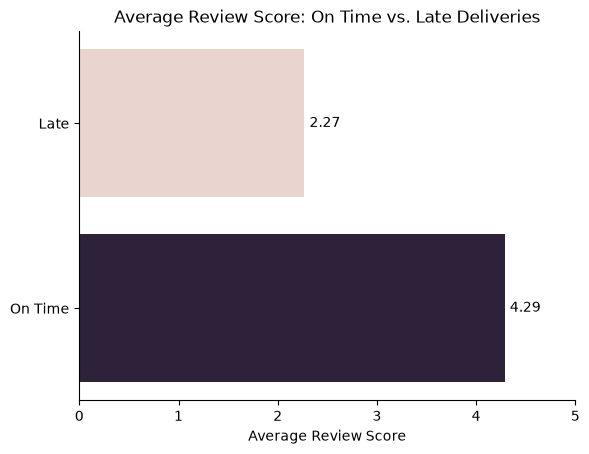

In [5]:
df_plot = df.groupby('delivery')['review_score'].mean().round(2).to_frame().reset_index()

sns.barplot(df_plot, x='review_score', y='delivery', hue='review_score', legend=False)
sns.despine()

for i, value in enumerate(df_plot['review_score']):
    plt.text(value + 0.05, i, f'{value:.2f}', va='center')

plt.title('Average Review Score: On Time vs. Late Deliveries')
plt.xlabel('Average Review Score')
plt.ylabel('')
plt.xlim(0, 5)
plt.savefig('images/delivery_vs_reviews_overview.png', bbox_inches='tight')
plt.show()

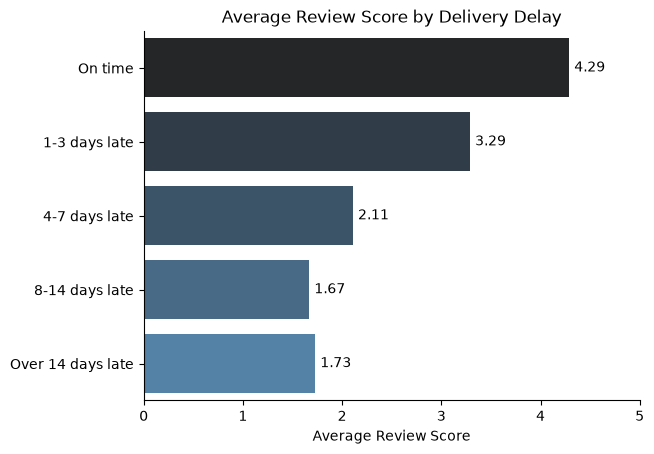

In [6]:
# Does the score keep dropping the later the order arrives?
# A function puts every order into a delay group.

def delay_group(days):
    if days <= 0:
        return 'On time'
    elif days <= 3:
        return '1-3 days late'
    elif days <= 7:
        return '4-7 days late'
    elif days <= 14:
        return '8-14 days late'
    else:
        return 'Over 14 days late'

df['delay_group'] = df['days_late'].apply(delay_group)

group_order = ['On time', '1-3 days late', '4-7 days late', '8-14 days late', 'Over 14 days late']

delay_stats = df.groupby('delay_group')['review_score'].agg(['count', 'mean']).loc[group_order]

df_plot = delay_stats.round(2).reset_index()

sns.barplot(df_plot, x='mean', y='delay_group', hue='delay_group', palette='dark:steelblue')
sns.despine()

for i, value in enumerate(df_plot['mean']):
    plt.text(value + 0.05, i, f'{value:.2f}', va='center')

plt.title('Average Review Score by Delivery Delay')
plt.xlabel('Average Review Score')
plt.ylabel('')
plt.xlim(0, 5)
plt.savefig('images/delivery_vs_reviews_by_delay.png', bbox_inches='tight')
plt.show()